In [1]:
import os
import re
import string

from pathlib import Path
from collections import Counter
from itertools import chain

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import plotly.graph_objects as go
from scipy.interpolate import make_interp_spline

from matplotlib.colors import ListedColormap
from tqdm.notebook import tqdm
from lxml import etree
from gensim.models import Word2Vec, FastText

import umap
import hdbscan

from adjustText import adjust_text

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

HOOFDKLEUR = '#007044'
PALET = ['#0067B9', '#FF9527', '#E100A3', '#9569BE', '#007044', '#00859B', '#CC982F',
         '#F275D4', '#59C0D1', '#4A5B84', '#FFD200', '#1A915E', '#27376B']
KLEUREN_GROEPEN = {'lawijd': '#0067B9', 'lawaai': '#E100A3', 'rumoer': '#FF9527',
                   'kabaal': '#9569BE', 'gerucht': '#007044'}

plt.rcParams.update({
    'font.family': 'Libertinus Serif',
    'font.size': CORPS,
    
    'axes.titlesize': CORPS,
    'axes.labelsize': CORPS,
    'xtick.labelsize': CORPS,
    'ytick.labelsize': CORPS,
    'legend.fontsize': CORPS,
    
    'figure.figsize': (TEKSTBREEDTE, TEKSTBREEDTE * 0.66),
})

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
xml_dir = Path("../../../data/algemeen/gebeurtenisdata_NER_XML")

fig_dir = Path("../../../fig/H8")
tab_dir = Path("../../../tab/H8")

In [4]:
meta = pd.read_excel("../../../data/H8/word-embeddings/gebeurtenisboeken.xlsx")
print(meta.columns.tolist())
start_year = 1876
end_year = 1939
meta = meta[(meta["year"] >= start_year) & (meta["year"] <= end_year)].copy()

['ID', 'archive_file', 'year', 'district', 'url-to-scan(pdf)']


In [5]:
def extract_text(filepath):
    tree = etree.parse(filepath)
    root = tree.getroot()

    keep_tags = {"page", "incident", "p", "marg"}
    for el in root.iter():
        if el.tag not in keep_tags:
            el.text = "_"
            el.tail = el.tail

    incidents = root.xpath(".//incident")
    texts = []
    for incident in incidents:
        text = " ".join(el.strip() for el in incident.itertext() if el.strip())
        texts.append(text)
    return texts

In [6]:
data = []

for _, row in meta.iterrows():
    filename = row["archive_file"] + "_final.xml"
    filepath = os.path.join(xml_dir, filename)

    texts = extract_text(filepath)
    for text in texts:
        data.append({
            "text":     text,
            "year":     row["year"],
            "district": row["district"],
        })

print(f"{len(data)} gebeurtenissen")

299597 gebeurtenissen


In [7]:
df = pd.DataFrame(data)
print(df.shape)
print(df.head())
print(df["year"].value_counts().sort_index())
print(df["district"].value_counts().sort_index())

(299597, 3)
                                                text  year  district
0  _ _ _ van 6 tot 12 BDUu 1 a 8 De _ _ _ _ _ hee...  1876         5
1  _ _ _ van _ _ wittigel t dat hij tig is me Kla...  1876         5
2  _ _ _ , won _ _ , verzoekt dat haren _ _ _ hed...  1876         5
3  _ le Comm des Pompiers a ete prie de mettre a ...  1876         5
4  agent _ _ a ete outrage pendant l ' exercice s...  1876         5
year
1876     1352
1877     3476
1878     3783
1879     1667
1880     3442
1881     1196
1882     3846
1883     2587
1884     2283
1885     3018
1886     4147
1887     4289
1888     3060
1889     6218
1890     6709
1891     3768
1892     4102
1893      960
1894     2287
1895     2527
1896     3741
1899     1212
1900     1110
1901     2654
1902     2879
1903     1758
1904     1549
1905     1299
1907     1206
1908     2622
1909     1060
1910     5281
1911     4566
1912     5597
1913    10506
1914     5526
1915     2882
1916     4905
1918     1937
1919     2457
1920     

In [8]:
def clean_text(text):
    tokens = text.split()
    tokens = [t.lower() for t in tokens]

    re_punc = re.compile("[%s]" % re.escape(string.punctuation))
    tokens = [re_punc.sub("", token) for token in tokens]
    
    tokens = [token for token in tokens if token.isalpha() and token != "_"]

    return tokens

df["tokens"] = df["text"].apply(clean_text)
df = df[df["tokens"].map(len) > 0].reset_index(drop=True)

print(f"{len(df)} gebeurtenissen")
print(df['tokens'].iloc[0][:15])

292472 gebeurtenissen
['van', 'tot', 'bduu', 'a', 'de', 'heeftheden', 'rond', 'in', 'de', 'bij', 'neven', 'tiedel', 'de', 'schapen', 'een']


In [9]:
#gemiddelde lengte gebeurtenis
df["token_count"] = df["tokens"].map(len)
print(df["token_count"].describe())

print(f"\nminder dan 10 tokens: {(df['token_count'] < 10).sum()}")
print(df[df["token_count"] < 10]["tokens"].head(10))

count    292472.000000
mean         39.981526
std          40.699773
min           1.000000
25%          12.000000
50%          28.000000
75%          52.000000
max         366.000000
Name: token_count, dtype: float64

minder dan 10 tokens: 56373
12             [niets, niets, nuts, nuts, niets, niets]
21                              [vande, walle, willeme]
29                                              [walle]
47    [wegens, nachtrntstodrnes, prs, veeb, zal, opg...
55                           [ompelin, van, dot, niets]
57                             [walle, a, en, van, tot]
58                                [niets, neuws, niets]
65                                  [dito, ende, walle]
66                       [bugrenne, vd, walle, willeme]
71                                              [schou]
Name: tokens, dtype: object


In [10]:
df = df[df["token_count"] >= 10].reset_index(drop=True)
print(f"zonder gebeurtenissen onder 10 tokens: {len(df)}")

zonder gebeurtenissen onder 10 tokens: 236099


In [11]:
all_tokens = [token for tokens in df["tokens"] for token in tokens]
vocab = Counter(all_tokens)

print(f"totaal tokens:       {len(all_tokens):,}")
print(f"unieke woorden:      {len(vocab):,}")
print(f"\ntop 30 meest frequent:")
for word, count in vocab.most_common(30):
    print(f"  {word:<20} {count:>8,}")

print(f"\nwoorden die maar 1x voorkomen: {sum(1 for c in vocab.values() if c == 1):,}")
print(f"woorden die < 5x voorkomen:    {sum(1 for c in vocab.values() if c < 5):,}")

totaal tokens:       11,439,447
unieke woorden:      595,667

top 30 meest frequent:
  de                    551,555
  van                   368,795
  en                    293,298
  te                    262,442
  het                   253,863
  den                   221,417
  in                    199,314
  op                    176,912
  om                    163,906
  ik                    157,348
  dat                   114,988
  aan                   110,716
  een                   109,127
  d                     108,684
  heden                 104,898
  n                      98,504
  met                    90,866
  door                   87,249
  voor                   82,701
  wonende                78,716
  heb                    78,535
  der                    71,589
  geb                    69,012
  er                     66,476
  is                     64,456
  agent                  64,425
  was                    63,899
  naar                   62,120
  genaamde         

In [12]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

nl_stopwords = set(stopwords.words('dutch'))

extra_words = {
    'den', 'ten', 'ter', 'eene', 'een', 'geb', 'won', 'dewelke', 'wij',
    'bureel', 'bureele', 'heden', 'genaamde', 'geboren', 'dienst',
    'wonende', 'agent', 'huis', 'auto', 'plaats', 'gedaan', 'kwam',
    'rond', 'persoon', 'weg', 'wijk', 'oud', 'agenten', 'bestatigd',
    'eenen', 'zijne',
    'staat', 'politie', 'welke', 'vastgesteld', 'bevel', 'fr', 'overgebracht',
    'gebracht', 'aldaar', 'la', 'le', 'id', 'wegens', 'genaamden', 'waar',
    'volgende', 'zijnde', 'et', 'mijne', 'antwerpen', 'des', 'tusschen',
    'post', 'waarvan', 'enz', 'woonende', 'beroep', 'commissaris', 'plichten',
    'bon', 'du', 'hare', 'langs', 'toe', 'achter', 'get', 'uur', 'kwartier',
    'ne', 'zijnen',
}

nl_stopwords.update(extra_words)

df['tokens'] = df['tokens'].apply(
    lambda tokens: [t for t in tokens if t not in nl_stopwords and len(t) > 1]
)

df['token_count'] = df['tokens'].map(len)
df = df[df['token_count'] >= 5].reset_index(drop=True)

print(f'{len(df)} gebeurtenissen')

all_tokens = [t for tokens in df['tokens'] for t in tokens]
vocab = Counter(all_tokens)
print(f'{len(all_tokens):,} tokens')
print(f'{len(vocab):,} unieke woorden')

217960 gebeurtenissen


4,682,926 tokens
590,415 unieke woorden


In [13]:
sentences = df["tokens"].tolist()

#model = Word2Vec(
#    sentences=sentences,
#    window=10,        
#    min_count=10,     
#    workers=4,       
#    epochs=10,       
#    sg=1,            
#    vector_size=100, 
#)

#model.save("word2vec.model")
#print(f"Model opgeslagen")

In [14]:
w2vmodel = Word2Vec.load("../../../data/H8/word-embeddings/word2vec.model")

In [15]:
#model = FastText(
#    sentences=sentences,
#    window=10,        
#    min_count=10,     
#    workers=4,       
#    epochs=10,       
#    sg=1,            
#    vector_size=100, 
#)

#model.save("FastText.model")

In [16]:
#model = FastText(
#    sentences=sentences,
#    window=10,        
#    min_count=1,     
#    workers=4,       
#    epochs=10,       
#    sg=1,            
#    vector_size=100, 
#)

#model.save("FastText_htr.model")

In [17]:
alle_woorden = w2vmodel.wv.index_to_key
alle_vectoren = w2vmodel.wv[alle_woorden]
index = {w: i for i, w in enumerate(alle_woorden)}

In [18]:
fasttextmodel = FastText.load("../../../data/H8/word-embeddings/FastText.model")
fasttext_htr_model =  FastText.load("../../../data/H8/word-embeddings/FastText_htr.model")

In [19]:
woord = 'lawaai'
n = 10

fasttext_top10 = fasttextmodel.wv.most_similar(woord, topn=n)
w2v_top10 = w2vmodel.wv.most_similar(woord, topn=n)

df_neighbours = pd.DataFrame({
    'FastText naburig woord': [w for w, sim in fasttext_top10],
    'FastText cos sim': [sim for w, sim in fasttext_top10],
    'Word2Vec naburig woord': [w for w, sim in w2v_top10],
    'Word2Vec cos sim': [sim for w, sim in w2v_top10]
})

df_neighbours.to_csv('../../../tab/H8/8.1_nearest_neighbours_lawaai.csv', index=False)

df_neighbours

,FastText naburig woord,FastText cos sim,Word2Vec naburig woord,Word2Vec cos sim
0,nachtlawaai,0.862816,ruzie,0.772140
1,lawaar,0.836665,lewijd,0.758719
2,nachtlawijt,0.779533,gerucht,0.739246
3,nachtlawijd,0.762011,nachtlawijt,0.731293
4,lawijd,0.756007,rusie,0.729543
5,lawid,0.754239,rumoer,0.727105
6,krakeel,0.748403,nachtlawaai,0.716433
7,nachtlawyd,0.746424,krakeel,0.714837
8,lawit,0.744666,tierde,0.704948
9,lawijdt,0.737686,aardt,0.702498


In [20]:
fasttext_htr = pd.DataFrame({
    'woord': ['lawijd', 'gerucht', 'rumoer', 'kabaal', 'lawaai'],
    'freq': [573, 509, 134, 259, 137],
    'nacht_woord': ['nachtlawijd', 'nachtgerucht', 'nachtrumoer', 'nachtkabaal', 'nachtlawaai'],
    'nacht_freq': [214, 122, 150, 2, 62]
})

fasttext_htr['totaal'] = fasttext_htr['freq'] + fasttext_htr['nacht_freq']

fasttext_htr.loc['totaal'] = [
    'totaal',
    fasttext_htr['freq'].sum(),
    '',
    fasttext_htr['nacht_freq'].sum(),
    fasttext_htr['totaal'].sum()
]

fasttext_htr.to_csv('../../../tab/H8/fasttext_htr.csv', index=False)

fasttext_htr

,woord,freq,nacht_woord,nacht_freq,totaal
0,lawijd,573,nachtlawijd,214,787
1,gerucht,509,nachtgerucht,122,631
2,rumoer,134,nachtrumoer,150,284
3,kabaal,259,nachtkabaal,2,261
4,lawaai,137,nachtlawaai,62,199
totaal,totaal,1612,,550,2162


In [21]:
UMAP_PARAMS = dict(n_neighbors=30, min_dist=0.0, n_components=2, random_state=42)
HDBSCAN_PARAMS = dict(min_cluster_size=50, min_samples=10)

# Projecties: één om te clusteren, één voor de figuur (Bijlage 1)
clusterable_embedding_all = umap.UMAP(**UMAP_PARAMS).fit_transform(alle_vectoren)
standard_embedding_all = umap.UMAP(random_state=42).fit_transform(alle_vectoren)

# Clustering
hdb = hdbscan.HDBSCAN(**HDBSCAN_PARAMS, gen_min_span_tree=True).fit(clusterable_embedding_all)
labels_all = hdb.labels_
clustered = labels_all >= 0

clusters = pd.DataFrame({
    'woord': alle_woorden,
    'cluster': labels_all,
    'freq': [w2vmodel.wv.get_vecattr(w, 'count') for w in alle_woorden],
})

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [22]:
clusters.to_csv( tab_dir / 'clusters_word2vec.csv', index=False)

In [23]:
ZOEKVORMEN = ['lawijd', 'gerucht', 'rumoer', 'kabaal', 'lawaai',
              'nachtlawijd', 'nachtgerucht', 'nachtrumoer', 'nachtlawaai', 'nachtrust', 'horen']

In [24]:
index = {w: i for i, w in enumerate(alle_woorden)}

In [25]:
# Clusters identificeren
cl = {naam: int(labels_all[index[w]]) for naam, w in [
    ('geluidsoverlast', 'nachtrust'),
    ('verbaal geweld', 'scheldwoorden'),
    ('muziek', 'muziek'),
    ('Frans', 'tapage'),
    ('bellen', 'belde')
]}


In [26]:
# Samenvatting
print(f"{len(alle_woorden)} woorden | {len(set(labels_all) - {-1})} clusters | "
      f"{clustered.sum()} geclusterd ({clustered.mean() * 100:.1f}%) | DBCV {hdb.relative_validity_:.3f}")
print('zoekvormen per cluster:', dict(Counter(int(labels_all[index[w]]) for w in ZOEKVORMEN)))

for naam, c in cl.items():
    top = clusters[clusters['cluster'] == c].nlargest(25, 'freq')['woord'].tolist()
    print(f"\n{naam} (cluster {c}, {(labels_all == c).sum()} woorden):\n{', '.join(top)}")

30468 woorden | 97 clusters | 16886 geclusterd (55.4%) | DBCV 0.286
zoekvormen per cluster: {27: 8, 21: 1, 72: 1, 83: 1}

geluidsoverlast (cluster 27, 112 woorden):
roepen, rust, inwoners, nachtrust, aard, stoorde, luidkeels, zingen, geburen, straten, storen, twisten, tieren, inwooners, luid, omliggende, stooren, gestoord, lawijd, aand, schreeuwen, stoorden, lawijt, lawaai, nachtgerucht

verbaal geweld (cluster 72, 339 woorden):
gij, zeggende, hebt, begon, antwoorde, riep, woorden, dief, zijt, antwoordde, uwe, smeerlap, hoer, gy, zit, zaken, kunt, zeg, beleedigd, beter, wilt, uwen, affaire, zult, kalmte

muziek (cluster 21, 134 woorden):
herberg, cafe, gehouden, drank, publiek, verbruikers, lokaal, muziek, dansen, gerucht, houder, houdster, geluid, orgel, verbruiker, koppels, uitbater, herber, dienster, bafe, herbergier, toegankelijk, gespeeld, gezongen, bediend

Frans (cluster 96, 505 woorden):
que, les, qu, qui, etait, nous, avait, elle, maison, cette, avons, chez, avec, etant, mais,

In [27]:
#genormaliseerde termen op basis van fasttext en word2vec
varianten_lawijd = [
    'lawijd',    # freq=170
    'lawijdt',   # freq=10
    'lawijt',    # freq=113
    'lawit',     # freq=12
    'lawid',     # freq=11
    'lawyjd',    # freq=12
    'lawyt',     # freq=28
    'lewijd',    # freq=10
    'lawyd',     # freq=41
]

varianten_lawaai = [
    'lawaai',    # freq=110
    'lawaar',    # freq=17
]

varianten_nachtlawijd = [
    'nachtlawijd',   # freq=87
    'nachtlawijt',   # freq=14
    'nachtlawyd',    # freq=12
]

varianten_nachtrumoer = [
    'nachtrumoer',   # freq=77   
    'nachtramoer',   # freq=11 ← twijfelgeval, variant van nachtrumoer?
    'nachtrumaer',   # freq=10 ← twijfelgeval
]

varianten_nachtlawaai = [
    'nachtlawaai',   # freq=35
    'nachtlangd',    # freq=10
]

varianten_rumoer = [
    'rumoer',    # freq=46
    'ramoer',    # freq=50
    'zamoer',    # freq=11 ← HTR-variant?
]

varianten_gerucht = [
    'gerucht',   # freq=405
    'gerugt',    # freq=11
    'gercht',    # freq=11 ← HTR-variant
]

varianten_kabaal = [
    'kabaal',    # freq=204
    'habaal',    # freq=19
]

varianten_nachtgerucht = [
    'nachtgerucht',  # freq=108
]

In [28]:
for w in ['ruzie', 'krakeel', 'twisten', 'tierde', 'luidruchtig', 'kabaal', 'bruit', 'bellen', 'gebeld', 'deur', 'hoorde']:
    c = int(labels_all[index[w]]) if w in index else None
    print(f"{w:<12} cluster {c}")

ruzie        cluster -1
krakeel      cluster 27
twisten      cluster 27
tierde       cluster 27
luidruchtig  cluster 27
kabaal       cluster 72
bruit        cluster 96
bellen       cluster 36
gebeld       cluster -1
deur         cluster 59
hoorde       cluster -1


In [29]:
print(clusters[clusters['cluster'] == 36].nlargest(25, 'freq')['woord'].tolist())

['voorbijgangers', 'lastig', 'bellen', 'ontucht', 'bedelen', 'leveren', 'ontving', 'inzicht', 'gangers', 'aansprak', 'voorbijganger', 'belde', 'sprak', 'opzieners', 'bedelde', 'almoezen', 'almoesen', 'bedelarij', 'manspersonen', 'bijgangers', 'gers', 'onzedige', 'aalmoezen', 'voorbygangers', 'lokken']


In [30]:
print(clusters[clusters['cluster'] == 83].nlargest(100, 'freq')['woord'].tolist())

['hi', 'zi', 'by', 'bi', 'zy', 'zine', 'wooning', 'lichten', 'zinen', 'zyne', 'mine', 'myne', 'mas', 'myn', 'maat', 'myj', 'bestendige', 'veer', 'gene', 'minen', 'aande', 'hom', 'zynen', 'maren', 'oms', 'kamen', 'wal', 'daen', 'hyj', 'anna', 'terwyl', 'neet', 'huren', 'hebb', 'horen', 'late', 'wuyts', 'meen', 'wede', 'gevon', 'myjne', 'hg', 'zyjne', 'byj', 'lid', 'hoeden', 'dek', 'deet', 'kel', 'zaan', 'tigen', 'gerard', 'maker', 'beng', 'waes', 'beveren', 'kinde', 'vrouws', 'zyj', 'boeck', 'vrauw', 'heiden', 'myjn', 'vak', 'ween', 'hemr', 'berit', 'soen', 'heelen', 'weert', 'geword', 'gelagen', 'vals', 'mett', 'hemn', 'berge', 'hemen', 'geween', 'verzeker', 'guig', 'onderzockt', 'peroon', 'daot', 'rind', 'bevend', 'villen', 'eij', 'smolders', 'hab', 'paulus', 'huen', 'bloek', 'rocht', 'termyl', 'waare', 'lasen', 'kae', 'brenden', 'plaatser', 'iner']


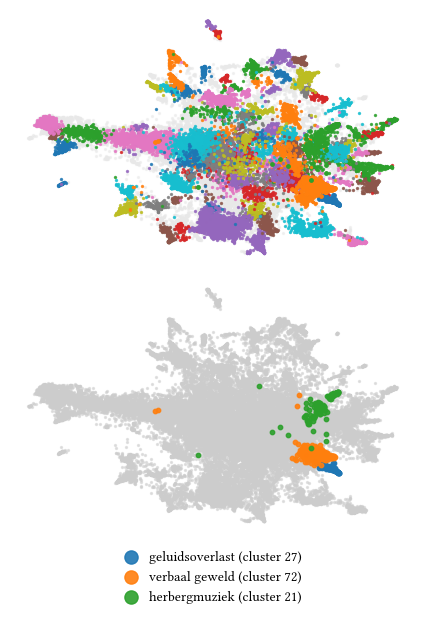

In [31]:
xy = standard_embedding_all

kleuren = plt.rcParams['axes.prop_cycle'].by_key()['color']

te_markeren = [
    (cl['geluidsoverlast'], kleuren[0], 'geluidsoverlast'),
    (cl['verbaal geweld'], kleuren[1], 'verbaal geweld'),
    (cl['muziek'], kleuren[2], 'herbergmuziek'),
]

fig, axes = plt.subplots(2, 1, figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 1.4), gridspec_kw={'hspace': 0.05})

# Boven: alle clusters in eigen kleur, ruis in lichtgrijs
axes[0].scatter(*xy[~clustered].T, s=2, color='#e8e8e8', alpha=0.5)
for i, cluster_id in enumerate(sorted(set(labels_all) - {-1})):
    axes[0].scatter(*xy[labels_all == cluster_id].T, s=2, alpha=0.8,
                    color=kleuren[i % len(kleuren)])
for cluster_id, kleur, _ in te_markeren:
    axes[0].scatter(*xy[labels_all == cluster_id].T, s=6, color=kleur, alpha=1, zorder=5)

# Onder: alles grijs, behalve de drie clusters
axes[1].scatter(*xy.T, s=2, color='#cccccc', alpha=0.5)
for cluster_id, kleur, label in te_markeren:
    axes[1].scatter(*xy[labels_all == cluster_id].T, s=10, color=kleur, alpha=0.9,
                    zorder=5, label=f'{label} (cluster {cluster_id})')

axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.02),
               frameon=False, markerscale=3, handlelength=1)

for ax in axes:
    ax.axis('off')

plt.subplots_adjust(hspace=0.05, bottom=0.12, left=0, right=1, top=1)

pas_breedte_aan(fig, tight=True)
fig.savefig(fig_dir/'8.2_clusters.png', dpi=300, bbox_inches='tight')
#fig.savefig(fig_dir/'8.2_clusters.pdf', bbox_inches='tight')
plt.show()

In [32]:
groepen_samengevoegd = {
    'lawijd':  varianten_lawijd + varianten_nachtlawijd,
    'lawaai':  varianten_lawaai + varianten_nachtlawaai,
    'rumoer':  varianten_rumoer + varianten_nachtrumoer,
    'kabaal':  varianten_kabaal,
    'gerucht': varianten_gerucht + varianten_nachtgerucht,
}

In [33]:
rijen = []
for jaar, deel in df.groupby('year'):
    telling_jaar = Counter(chain.from_iterable(deel['tokens']))
    n_tokens = sum(telling_jaar.values())
    rijen.append({'jaar': jaar} | {g: sum(telling_jaar[w] for w in v) / n_tokens * 10_000
                                   for g, v in groepen_samengevoegd.items()})

per_jaar = pd.DataFrame(rijen).set_index('jaar').sort_index()

jaren = per_jaar.index.to_numpy()
tienjaarlijks = pd.DataFrame(
    {g: [per_jaar[g][np.abs(jaren - j) <= 5].mean() for j in jaren] for g in per_jaar},
    index=jaren,
).rename_axis('jaar')

#per_jaar.round(3).to_csv(tab / 'afbeelding1_per_jaar.csv')
#tienjaarlijks.round(3).to_csv(tab / 'afbeelding1_tienjaarlijks_gemiddelde.csv')
tienjaarlijks.tail()

,lawijd,lawaai,rumoer,kabaal,gerucht
jaar,,,,,
1935,0.195906,0.265632,0.169262,0.826422,0.815237
1936,0.202502,0.249630,0.127381,0.690666,0.814787
1937,0.214833,0.215928,0.117341,0.647187,0.773842
1938,0.170320,0.246775,0.112617,0.599979,0.755471
1939,0.181446,0.236121,0.114125,0.630931,0.795077


In [34]:
totaal_per_jaar = tienjaarlijks.sum(axis=1)
jaren = totaal_per_jaar.index.to_numpy(dtype=float)

x_smooth = np.linspace(jaren.min(), jaren.max(), 300)
y_smooth = make_interp_spline(jaren, totaal_per_jaar.to_numpy(), k=3)(x_smooth)
y_smooth = np.clip(y_smooth, 0, None)   # spline kan onder nul duiken

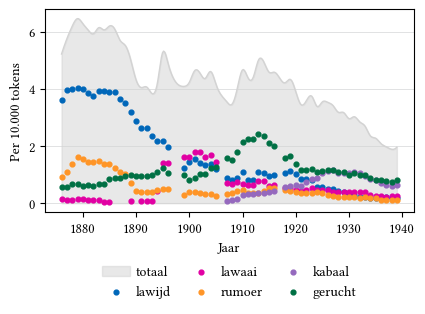

In [35]:
fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.62))

ax.fill_between(x_smooth, y_smooth, alpha=0.5, color='lightgrey', label='totaal')
ax.plot(x_smooth, y_smooth, color='lightgrey', alpha=1, linewidth=1)

for groepnaam, kleur in KLEUREN_GROEPEN.items():
    zichtbaar = tienjaarlijks[groepnaam] >= 0.05
    ax.scatter(jaren[zichtbaar], tienjaarlijks[groepnaam][zichtbaar],
               s=12, color=kleur, label=groepnaam, zorder=3)

ax.set_xlabel('Jaar')
ax.set_ylabel('Per 10.000 tokens')
ax.grid(axis="y")
ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center', ncol=3, frameon=False,
          columnspacing=1.2, handletextpad=0.4)

pas_breedte_aan(fig, tight=True)
fig.savefig(fig_dir / '8.3_relatieve_frequentie.png', dpi=300, bbox_inches='tight')
#fig.savefig(FIG_DIR / '8.3_relatieve_frequentie.pdf', bbox_inches='tight')

In [36]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
DOEL_PT = 7           # lettergrootte op papier
CANVAS_BREEDTE = 1300
CANVAS_HOOGTE = 950

FONT = round(DOEL_PT * CANVAS_BREEDTE / (TEKSTBREEDTE * 72))   # 21
FONT_GROEP = FONT + 4

In [37]:
def maak_semantisch_veld(groepen, model, topn=100, label_drempel=None, bestand=None):
    """Semantisch veld rond groepen van varianten. label_drempel=None labelt alle woorden."""
    woorden, woord_groep = [], {}

    for groepnaam, varianten in groepen.items():
        varianten_model = [w for w in varianten if w in model.wv]
        if not varianten_model:
            continue

        gem_vector = np.mean([model.wv[w] for w in varianten_model], axis=0)
        buren = [w for w, _ in model.wv.similar_by_vector(gem_vector, topn=topn) if w not in varianten]

        for w in varianten_model:
            woord_groep.setdefault(w, groepnaam)
        woorden += [w for w in varianten_model + buren if w not in woorden]

    embedding = umap.UMAP(random_state=42).fit_transform(model.wv[woorden])

    freqs = np.array([model.wv.get_vecattr(w, 'count') for w in woorden])
    log_max = np.log1p(freqs).max()
    grootte = lambda f: 5 + np.log1p(f) / log_max * 30
    sizes = grootte(freqs)

    def label(i):
        return woorden[i] if label_drempel is None or freqs[i] >= label_drempel else ''

    fig = go.Figure()

    # Naburige woorden
    buren_idx = [i for i, w in enumerate(woorden) if w not in woord_groep]
    fig.add_trace(go.Scatter(
        x=embedding[buren_idx, 0], y=embedding[buren_idx, 1],
        mode='markers+text', name='naburige woorden',
        text=[label(i) for i in buren_idx], textposition='top center',
        textfont=dict(size=FONT, color='#555555'),
        marker=dict(size=sizes[buren_idx], color='#dddddd', opacity=0.8, line=dict(width=0)),
        hovertext=[f'<b>{woorden[i]}</b><br>frequentie: {freqs[i]}' for i in buren_idx],
        hoverinfo='text',
    ))

    # Varianten per groep en groepscentra
    for groepnaam, kleur in KLEUREN_GROEPEN.items():
        idx = [i for i, w in enumerate(woorden) if woord_groep.get(w) == groepnaam]
        if not idx:
            continue

        fig.add_trace(go.Scatter(
            x=embedding[idx, 0], y=embedding[idx, 1],
            mode='markers+text', name=groepnaam,
            text=[f'<b>{woorden[i]}</b>' for i in idx], textposition='top center',
            textfont=dict(size=FONT, color=kleur),
            marker=dict(size=sizes[idx], color=kleur, opacity=0.9, line=dict(width=0)),
            hovertext=[f'<b>{woorden[i]}</b> ({groepnaam})<br>frequentie: {freqs[i]}' for i in idx],
            hoverinfo='text',
        ))

        x, y = embedding[idx].mean(axis=0)
        fig.add_trace(go.Scatter(
            x=[x], y=[y], mode='markers+text', showlegend=False,
            text=[f'<b>{groepnaam}</b>'], textposition='top center',
            textfont=dict(size=FONT_GROEP, color=kleur),
            marker=dict(size=35, color=kleur, line=dict(width=2, color='white')),
            hoverinfo='skip',
        ))

    # Groottelegende
    for f in (10, 100, 1000):
        fig.add_trace(go.Scatter(
            x=[None], y=[None], mode='markers',
            marker=dict(size=grootte(f), color='#bbbbbb'),
            name=f'{f:,}'.replace(',', '.') + ' keer',
            legendgroup='frequentie', legendgrouptitle_text='corpusfrequentie',
        ))

    fig.update_layout(
        template='plotly_white',
        width=CANVAS_BREEDTE, height=CANVAS_HOOGTE,
        margin=dict(l=10, r=10, t=10, b=10),
        hovermode='closest',
        font=dict(family='Libertinus Serif', size=FONT),
        xaxis=dict(visible=False), yaxis=dict(visible=False),
        legend=dict(
            x=0.99, y=0.99, xanchor='right', yanchor='top',
            bgcolor='rgba(255,255,255,0.9)', bordercolor='lightgrey', borderwidth=1,
            itemsizing='trace',
        ),
    )

    if bestand:
        fig.write_image(f'{bestand}.png', scale=1.5)

    fig.show()
    return fig

In [38]:
fig = maak_semantisch_veld(
    groepen_samengevoegd,
    w2vmodel,
    topn=100
)

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [39]:
def semantisch_veld_data(groepen, model, topn=100):
    """Varianten en naburige woorden per groep, met hun UMAP-positie en frequentie."""
    woorden, woord_groep = [], {}
    for groepnaam, varianten in groepen.items():
        aanwezig = [w for w in varianten if w in model.wv]
        if not aanwezig:
            continue
        gem_vector = np.mean([model.wv[w] for w in aanwezig], axis=0)
        buren = [w for w, _ in model.wv.similar_by_vector(gem_vector, topn=topn) if w not in varianten]
        for w in aanwezig:
            woord_groep.setdefault(w, groepnaam)
        woorden += [w for w in aanwezig + buren if w not in woorden]

    xy = umap.UMAP(random_state=42).fit_transform(np.array([model.wv[w] for w in woorden]))
    return pd.DataFrame({
        'woord': woorden, 'x': xy[:, 0], 'y': xy[:, 1],
        'freq': [model.wv.get_vecattr(w, 'count') for w in woorden],
        'groep': [woord_groep.get(w) for w in woorden],
    })

In [40]:
from difflib import SequenceMatcher
from adjustText import adjust_text
from matplotlib.lines import Line2D


def semantisch_veld_data(groepen, model, topn=100):
    """Varianten en naburige woorden per groep, met hun UMAP-positie en frequentie."""
    woorden, woord_groep = [], {}
    for groepnaam, varianten in groepen.items():
        aanwezig = [w for w in varianten if w in model.wv]
        if not aanwezig:
            continue
        gem_vector = np.mean([model.wv[w] for w in aanwezig], axis=0)
        buren = [w for w, _ in model.wv.similar_by_vector(gem_vector, topn=topn) if w not in varianten]
        for w in aanwezig:
            woord_groep.setdefault(w, groepnaam)
        woorden += [w for w in aanwezig + buren if w not in woorden]

    xy = umap.UMAP(random_state=42).fit_transform(np.array([model.wv[w] for w in woorden]))
    return pd.DataFrame({
        'woord': woorden, 'x': xy[:, 0], 'y': xy[:, 1],
        'freq': [model.wv.get_vecattr(w, 'count') for w in woorden],
        'groep': [woord_groep.get(w) for w in woorden],
    })


def normaliseer_buren(veld, drempel=0.8):
    """Koppel spellingsvarianten van naburige woorden aan hun frequentste vorm."""
    is_variant = lambda a, b: SequenceMatcher(None, a.replace('y', 'ij'), b.replace('y', 'ij')).ratio() >= drempel
    normalisatie, lemmas = {}, []
    for w in veld.loc[veld['groep'].isna()].sort_values('freq', ascending=False)['woord']:
        lemma = next((l for l in lemmas if is_variant(w, l)), None)
        if lemma:
            normalisatie[w] = lemma
        else:
            lemmas.append(w)
    return normalisatie


def plot_semantisch_veld(veld, normalisatie=None, label_drempel=0, legende='lower right', bestand=None):
    """Statische versie voor druk: één label per woord (niet per spellingsvariant)."""
    normalisatie = normalisatie or {}
    log_max = np.log1p(veld['freq']).max()
    oppervlakte = lambda f: 3 + np.log1p(f) / log_max * 40
    grootte = oppervlakte(veld['freq'])
    buren = veld[veld['groep'].isna()].sort_values('freq', ascending=False)

    fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    ax.scatter(buren['x'], buren['y'], s=grootte[buren.index], color='#dddddd', linewidth=0, zorder=1)

    teksten, gelabeld = [], set()
    for _, r in buren.iterrows():
        lemma = normalisatie.get(r['woord'], r['woord'])
        if lemma not in gelabeld and r['freq'] >= label_drempel:
            gelabeld.add(lemma)
            teksten.append(ax.text(r['x'], r['y'], r['woord'], fontsize=CORPS_KLEIN, color='#555555'))

    for groep, kleur in KLEUREN_GROEPEN.items():
        deel = veld[veld['groep'] == groep]
        ax.scatter(deel['x'], deel['y'], s=grootte[deel.index], color=kleur, linewidth=0, alpha=0.8, zorder=2)
        x, y = deel['x'].mean(), deel['y'].mean()
        ax.scatter(x, y, s=90, color=kleur, edgecolor='white', linewidth=1.2, zorder=3)
        teksten.append(ax.text(x, y, groep, fontsize=CORPS_KLEIN, fontweight='bold', color=kleur, zorder=4))

    # Legende: groepen en corpusfrequentie (markersize is een diameter, dus vierkantswortel)
    punt = lambda f: np.sqrt(oppervlakte(f))
    handles = [Line2D([], [], marker='o', ls='', color='#dddddd', markersize=punt(100), label='naburige woorden')]
    handles += [Line2D([], [], marker='o', ls='', color=k, markersize=punt(100), label=g)
                for g, k in KLEUREN_GROEPEN.items()]
    handles += [Line2D([], [], ls='', label='corpusfrequentie')]
    handles += [Line2D([], [], marker='o', ls='', color='#bbbbbb', markersize=punt(f),
                       label=f'{f:,}'.replace(',', '.') + ' keer')
                for f in (10, 100, 1000)]
    # legende onder de figuur, in twee kolommen: links de groepen, rechts de frequenties
    handles += [Line2D([], [], ls='', label='')] * 2
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2,
              fontsize=CORPS, frameon=False, handletextpad=0.4, columnspacing=2.0)

    adjust_text(teksten, ax=ax, arrowprops=dict(arrowstyle='-', color='0.7', lw=0.4))
    ax.axis('off')

    if bestand:
        pas_breedte_aan(fig, tight=True)
        fig.savefig(f'{bestand}.png', dpi=300, bbox_inches='tight')
    plt.show()
    return fig

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


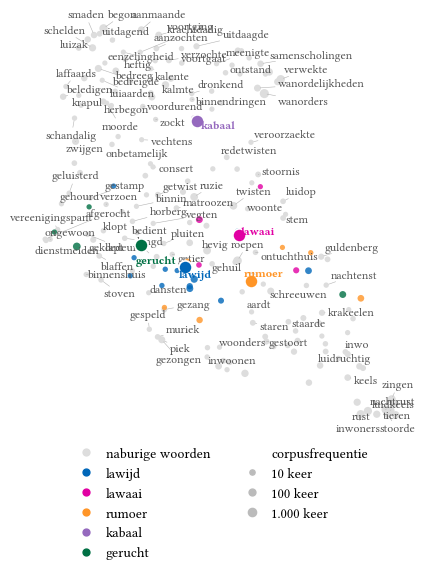

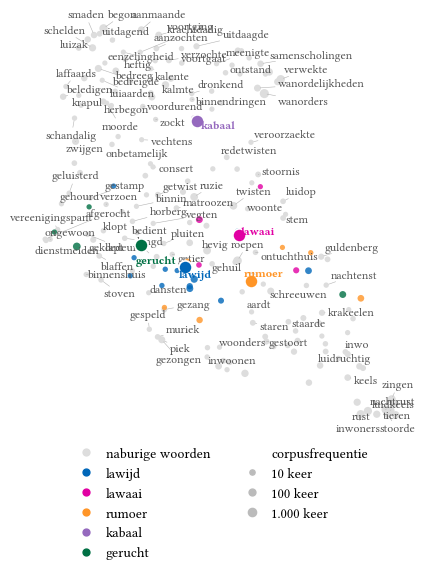

In [41]:
veld = semantisch_veld_data(groepen_samengevoegd, w2vmodel)
normalisatie_neighbours = normaliseer_buren(veld)

plot_semantisch_veld(veld, normalisatie=normalisatie_neighbours, legende='upper right',
                     bestand=fig_dir / '8.4_semantisch_veld')

# interactieve versie met alle labels, voor de repository

In [42]:
len(veld)

206

In [43]:
# ---------------------------------------------------------
# Bijlage 10.3: top 10 naburige woorden per synoniem (genormaliseerd)
# ---------------------------------------------------------
# - per synoniem: gemiddelde vector van alle varianten (zoals in afbeelding 8.4)
# - de varianten van de vijf synoniemen zelf tellen niet als buur
# - spellingsvarianten van de buren worden gekoppeld aan hun frequentste vorm
#   (strenger dan normaliseer_buren: gelijkenis >= 0,85 en zelfde beginletter,
#   zodat bv. 'gehoord' en 'gestoord' niet samengevoegd worden)
# - score = hoogste cosinussimilariteit van een van de varianten
# - freq  = som van de corpusfrequenties van alle varianten (dus per woord overal gelijk)
# - enkel woorden met een frequentie van minstens 100

MIN_FREQ = 100
TOPN = 300
VOLGORDE_BIJLAGE = ['lawijd', 'kabaal', 'lawaai', 'rumoer', 'gerucht']

def naburige_woorden(groepen, model, topn=TOPN, min_freq=MIN_FREQ, n=10):
    tel = lambda w: model.wv.get_vecattr(w, 'count')
    is_variant = lambda a, b: (a[0] == b[0] and
        SequenceMatcher(None, a.replace('y', 'ij'), b.replace('y', 'ij')).ratio() >= 0.85)
    veldwoorden = {w for varianten in groepen.values() for w in varianten}

    buren = {}
    for groep, varianten in groepen.items():
        aanwezig = [w for w in varianten if w in model.wv]
        gem_vector = np.mean([model.wv[w] for w in aanwezig], axis=0)
        buren[groep] = [(w, s) for w, s in model.wv.similar_by_vector(gem_vector, topn=topn)
                        if w not in veldwoorden]

    alle_buren = sorted({w for b in buren.values() for w, _ in b}, key=tel, reverse=True)
    lemma, lemmas = {}, []
    for w in alle_buren:
        l = next((l for l in lemmas if is_variant(w, l)), None)
        lemma[w] = l or w
        if l is None:
            lemmas.append(w)

    freq = Counter()
    for w in alle_buren:
        freq[lemma[w]] += tel(w)

    rijen = []
    for groep in VOLGORDE_BIJLAGE:
        score = {}
        for w, s in buren[groep]:
            score[lemma[w]] = max(score.get(lemma[w], 0), s)
        top = sorted((l for l in score if freq[l] >= min_freq), key=lambda l: -score[l])[:n]
        for rang, l in enumerate(top, 1):
            rijen.append({
                'synoniem': groep,
                'rang': rang,
                'woord': l,
                'score': round(float(score[l]), 2),
                'freq': freq[l],
                'varianten': ', '.join(w for w in alle_buren if lemma[w] == l)
            })
    return pd.DataFrame(rijen)

naburig = naburige_woorden(groepen_samengevoegd, w2vmodel)
naburig.to_csv(tab_dir / '10.3_naburige_woorden.csv', index=False, sep=';', decimal=',')

In [44]:
for groep in VOLGORDE_BIJLAGE:
    print(f"\n{groep}")
    print(naburig[naburig['synoniem'] == groep][['woord', 'score', 'freq', 'varianten']].to_string(index=False))


lawijd
     woord  score  freq                                                                                   varianten
 luidkeels   0.89   706                              luidkeels, luidheels, luikeels, ludkeels, luitkeels, lindkeels
    tieren   0.84   386                                                                   tieren, tierende, tierden
   stoorde   0.83  1081                                stoorde, stooren, stoorden, stoonde, stoord, storden, stoode
 nachtrust   0.83   975                                       nachtrust, nachtruit, nachtrast, nachtrest, nachteust
schreeuwen   0.82   214                                  schreeuwen, schreuwen, schreeuwde, schreewen, schreeuwende
  inwoners   0.79  1433 inwoners, inwooners, inwoner, inwoonders, inwooner, inwonens, iwoners, inwonders, inwonners
     twist   0.78   733                                                                               twist, twiste
   zwijgen   0.78   174                                         